# Floating debris: what we tested and what we found

The platform maps floating debris from Sentinel-2 in three steps:

1. Keep pixels whose FDI and NDVI are both far above the month's water (mean + 3 sigma, the Digital Earth Africa rule).
2. Keep those a random forest trained on MARIDA calls debris with probability 0.5 or more.
3. Group what is left into patches.

This notebook asks two questions. Does the chain find debris it has not seen? And what are the patches it draws in Guinea?

It reads the saved results, so it runs in seconds. The scripts that made them are in `1_floating_debris`.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_colwidth", 60, "display.width", 180)
ROOT = Path(r"D:\Guinea_Methodology\plasticwaste_experiments")

OUT = ROOT / "1_floating_debris" / "outputs"

## 1. Does the chain find debris it has not seen?

MARIDA is the public benchmark of labelled Sentinel-2 debris. It has 14 tiles with debris labels.

The earlier recall of 0.886 came from the 2 easiest tiles. Here each tile is held out in turn: thresholds and forest are set without it, then it is scored. That is the fair test of a new place like Guinea. Pixels are pooled over the 14 tiles, and the intervals resample tiles.

In [2]:
scores = pd.read_csv(OUT / "01_loto_scores.csv")
scores[["method", "precision", "recall", "f1", "recall_p05", "recall_p95"]].sort_values("f1", ascending=False).round(2)

,method,precision,recall,f1,recall_p05,recall_p95
0,Random forest alone,0.83,0.84,0.84,0.79,0.87
1,"FDI rule, then forest",0.89,0.44,0.59,0.16,0.80
2,FDI mean+3sd,0.22,0.53,0.31,0.20,0.95
3,FAI mean+3sd,0.15,0.27,0.19,0.10,0.51
4,"Deployed: FDI and NDVI rule, then forest",0.82,0.09,0.16,0.04,0.22
5,PI mean+3sd,0.10,0.22,0.14,0.18,0.37
6,FDI and NDVI mean+3sd (rule deployed),0.14,0.13,0.13,0.06,0.33
7,FDI Otsu,0.00,0.45,0.01,0.25,0.70
8,Naive Bayes on NDVI-FDI (Biermann 2020),NaN,0.00,NaN,0.00,0.00


**Reading it.** Precision is how many detections are right. Recall is how much debris is found. The deployed chain is precise but finds about 9 % of the debris. The forest alone looks far better here, so the next sections test it on Guinean water.

One point of fairness: the rule's thresholds here come from MARIDA's labelled pixels. With thresholds from all the water, precision is 0.88 and recall 0.16, so the conclusion holds.

In [3]:
pd.read_csv(OUT / "06_fairness.csv").round(2)

,method,tp,fp,fn,precision,recall,f1
0,"FDI rule, all water",1964,356157,1435,0.01,0.58,0.01
1,"FDI and NDVI rule, all water",638,4122,2761,0.13,0.19,0.16
2,"FDI rule, all water, then forest",1617,311,1782,0.84,0.48,0.61
3,"Deployed chain, all water",528,74,2871,0.88,0.16,0.26
4,"Naive Bayes NDVI-FDI, equal priors",3091,48085,308,0.06,0.91,0.11


## 2. What is under the patches in Guinea?

We compared the published patches with two independent maps: the Murray global tidal flats and JRC surface water occurrence. JRC shows how often a pixel was water from 1984 onward, so a pixel under 90 % is not permanent water.

In [4]:
pd.read_csv(OUT / "04_patch_surfaces_summary.csv")

,region,patches,on_tidal_flat_map,within_150m_of_tidal_flat,occurrence_below_90,either
0,Conakry,26,22,22,22,22
1,Fatala,4,1,1,3,3
2,Whole coast,41,24,28,26,29
3,All,71,47,51,51,54


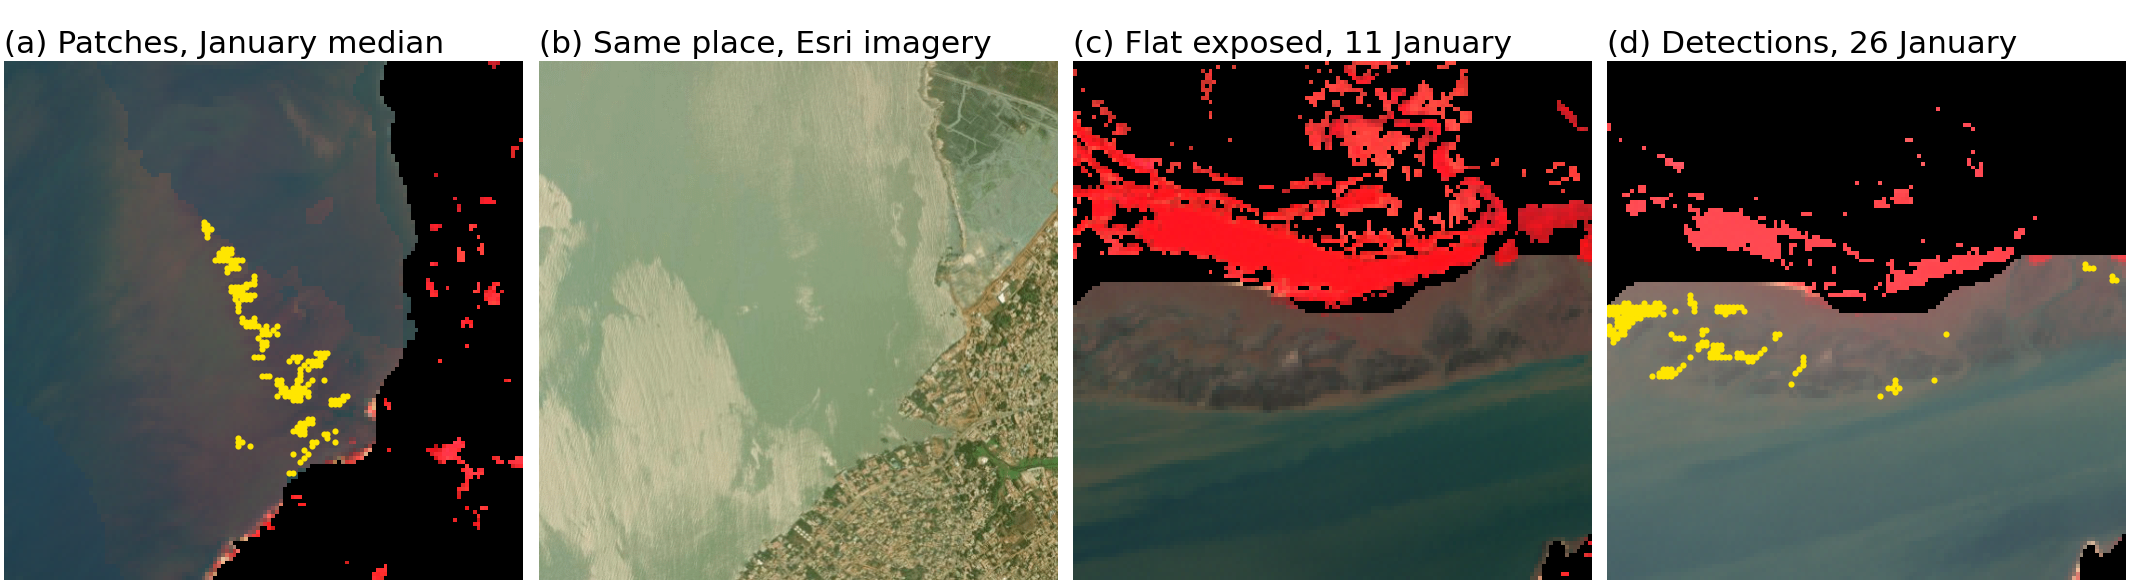

In [5]:
display(Image(str(OUT / "09_figure_tidal_flats.png"), width=900))

**Reading it.** At Conakry 22 of 26 January patches are on tidal flats, and the other test below shows all 242 pixels are on flats or non-permanent water. These flats are only 6 % of the water. MARIDA has almost no water like this: turbid, shallow and tidal.

## 3. Do the patches behave like something floating?

Floating material moves. Mud banks do not. We checked whether January's patches were still above the FDI threshold on the two clear dates of that month, and whether November's patches came back in the same place.

In [6]:
p = json.loads((OUT / "02_persistence.json").read_text())
print(f"January patches above the FDI threshold on both clear dates: {p['jan_fdi_above_thr_on_both']} of {p['jan_patches']}")
print(f"November patches beside a January patch: {p['nov_patches_within_1px_of_jan']} of {p['nov_patches']}")
print(f"Expected by chance: {p['expected_if_random']:.2f}, so about {p['enrichment']:.0f} times chance")

January patches above the FDI threshold on both clear dates: 20 of 26
November patches beside a January patch: 5 of 44
Expected by chance: 0.05, so about 102 times chance


**Reading it.** Most patches stay put. That points to fixed ground, not drifting debris. This is a first check, not yet a filter. Turning it into a proper test is planned for the weekend.

## 4. Why rainy months look empty

Each month's map is a median of cloud-free images. In the rainy season there are few or none, so an empty map often means the month could not be seen. It does not mean the water was clean.

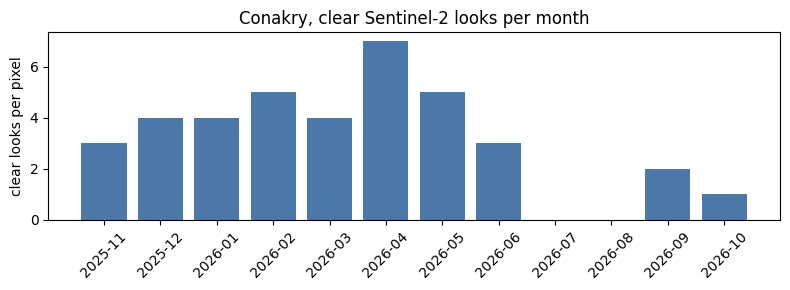

In [7]:
m = pd.read_csv(OUT / "05_scenes_per_month.csv")
m = m[m.region == "conakry"]
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(m.month, m.clear_median, color="#4c78a8")
ax.set_ylabel("clear looks per pixel")
ax.set_title("Conakry, clear Sentinel-2 looks per month")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()

## 5. Would another chain do better in Guinea?

We ran each candidate on Conakry twice: over the platform's water mask, and over a stricter tide-safe mask without the flats.

In [8]:
c = pd.read_csv(OUT / "07_candidates.csv")
c = c[c["product"].str.contains("median")]
c.pivot_table(index=["product", "chain"], columns="mask", values="px", aggfunc="first")

mask                                                deployed water  tide-safe water
product        chain                                                               
2023-11 median Deployed: FDI and NDVI, then forest             317                1
               FDI, then forest                              17461              368
               Forest alone                                  18142              368
2024-01 median Deployed: FDI and NDVI, then forest             242                0
               FDI, then forest                              15803             1177
               Forest alone                                  17502             1240

**Reading it.** The forest alone, the best method on MARIDA, draws thousands of pixels in Guinea, and about 93-98 % are on flats. With the flats removed, the deployed chain leaves 0-1 pixels. So the forest's high benchmark score does not carry over, and the deployed chain's patches are mostly flats.

Removing flats outright may be too strong, which is why the next step tests flagging them instead of deleting them.

## 6. Rivers

The rule fires on rivers, but almost entirely at the bank, where a 10 m pixel mixes land and water.

In [9]:
r = pd.read_csv(OUT / "08_river_tiles.csv")
r = r[r.valid]
print("Tiles with a usable threshold:", len(r))
print("Rule pixels:", r.rule_px.sum(), "of which over 40 m from the bank:", r.rule_px_over_40m.sum())
print("Pixels the classifier keeps:", r.deployed_px.sum())


Tiles with a usable threshold: 49
Rule pixels: 8673 of which over 40 m from the bank: 16
Pixels the classifier keeps: 0


## What this means

- The layer shows **candidates**, not confirmed debris.
- On unseen tiles it finds 9-16 % of the debris.
- In Guinea most patches are tidal flats or the turbid fringe.
- A better method needs confirmed debris labels from waters like Guinea's. None exist yet, and MARIDA's labels have their own uncertainty.

Planned next: flag tidal and persistent patches instead of deleting them, test the published detector of Rußwurm et al. (2023), and test Guinean flats as extra negative training data.